# Lab 1: Introduction to ScikitLearn, Preprocessing and Classification Tasks

During this Lab, we aim to achieve the following:


*   Get familiar with <a href="https://scikit-learn.org/stable/"> scikit-learn </a>, an essential python library in data science;
*   Get familiar with text preprocessing
*   learn how to approach a text classification task with scikit-learn.

In this notebook, we learn to use Scikit-Learn with a practical example and then, in the second part, we will test our knowledge by doing some exercises.



# Exercise 1: Zipf Law

I collected texts by Agatha Christie from the Gutenberg project:

  1. https://www.math.unipd.it/~dasan/christie.txt

You need to write a code to show to what extent those texts follow the Zipf law. The law states that, if we sort the words according to their frequency (from most to least frequent), the normalised frequency of the N-th word in a text roughly follows this rule $$\frac{1}{(N+b)^a}$$

for some parameters a,b.

We have seen the resulting plot in the first class of the course. See [this link for a short description.](https://phys.org/news/2017-08-unzipping-zipf-law-solution-century-old.html) of the Zipf law.

You are already given some snippets of code that allow you to:
  1. collect the texts given the url. In case the website is slow due to high traffic, while you are building the code you can test it on a small string you can extract from the text or create yourself.
  2. sort the dictionary of values according to the frequencies
  3. plot the word frequencies
  4. print the information to be copied on the Moodle when submitting your exercise.

You need to complete the code that preprocess the data and results in a dictionary whose keys are words and values their frequencies. You need to pay attention to what to consider as word (what do you compute frequency of). There are clearly some items that should be discarded because they are not words. Other preprocessing choices could make sense either way.

You can verify the Zipf law for the following texts as well:

  1. https://www.math.unipd.it/~dasan/shakespeare.txt
  2. https://www.math.unipd.it/~dasan/twain.txt
  3. https://www.math.unipd.it/~dasan/verne.txt

 This last part is not part of the lab-exercises, but we can discuss the results in class. Beware that the files are much larger, so do not run the code while in the lab. It is best to download the files once and modify the code to work locally.

In [1]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt
import sys
import requests
import string


def plot(freq, author, limit=-1):
  """
    freq: a list of ordered frequency values
    author: a string representing the author of the texts
    limit: how many words are being plotted
  """
  def func(x, a, b):
    return 1/((x+b) * np.exp(a))

  rank = list(range(1, len(freq)+1))
  maxf = max(freq)
  freq = [f/maxf for f in freq]

  #Plot the rank and frequency
  plt.plot(rank[:limit], freq[:limit], label=author)

  # Labelling the x axis
  plt.xlabel('Word Rank')
  # Labelling the y axis
  plt.ylabel('Frequency')

  bestparams, p = opt.curve_fit(func, rank, freq)
  plt.plot(rank[:limit], func(rank[:limit], *bestparams), label="fit")
  plt.text(limit-100, 0.15, "a=%.3f\nb=%.3f"%(bestparams[0], bestparams[1]))

  # Providing a title to the graph
  plt.title("Zipf's law")

  plt.legend()
  plt.show()
  return bestparams[0], bestparams[1]


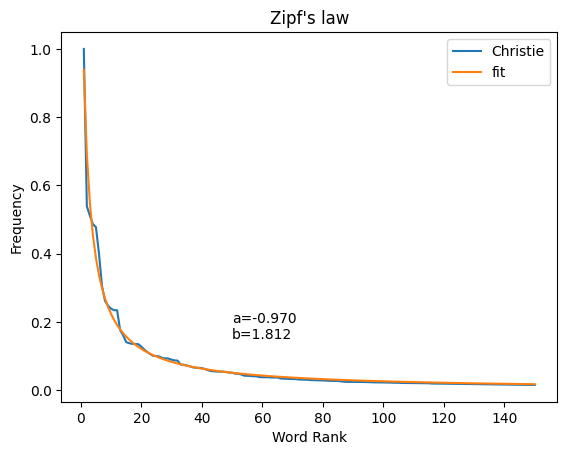

number of items =  37884
0 the 81782
1 and 44070
2 of 41819
3 to 39788
4 a 39075
5 i 32793
6 in 24992
7 he 21411
8 it 20236
9 was 19529
10 you 19168
11 that 19154
12 his 14372
13 with 13153
14 is 11507
15 as 11250
16 s 11102
17 for 11055
18 had 11025
19 at 10453
20 but 9723
21 not 9130
22 on 8606
23 her 8214
24 have 8185
a= -0.9704007113274378 b= 1.8120794295499922


In [2]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt
import sys
import requests
import string


input_file = "https://www.math.unipd.it/~dasan/christie.txt"


data = requests.get(input_file).text  # get the text from the url, data is a string
textDict = {} # the keys of the dictionary will be words, the values their frequencies


#### Add your code here to fill textDict

import nltk
from nltk.tokenize import RegexpTokenizer

# grab only word characters by using a regex
tokenizer = RegexpTokenizer(r'[a-zA-Z0-9_]+')
tokens = tokenizer.tokenize(data)
# putting everything in lowercase
tokens = [word.lower() for word in tokens]

# counting the frequencies
for word in tokens:
  if word in textDict:
    textDict[word] += 1
  else:
    textDict[word] = 1

####

textDict = dict(sorted(textDict.items(), key=lambda item: item[1], reverse=True)) # sort the words by frequency

a,b = plot(textDict.values(), "Christie", 150)

##### Copy all the text that is printed from the following commands in Moodle
print("number of items = ", len(textDict))
for i,t in enumerate(list(textDict.keys())[:25]):
  print(i, t, textDict[t])
print ("a=", a, "b=", b)


## Lab Assignment

Copy the output generated by the instructions below "##### Copy all the text that is printed from the following commands in Moodle" in the text box of the assignment on Moodle

#Sentiment Analysis

The dataset is described here: https://www.aclweb.org/anthology/P04-1035.pdf

It is part of nltk, so it is convenient for us to use.

The goal of this exercise is to build a first machine learning model using the tools that we have seen so far: choose how to preprocess the text, create a bag of words feature representation, train a model using an ML method of your choice.

You need to use the following split for the data:

*   test: 30% of the documents
*   The rest of the documents will be split as
    *   train: 75% of the documents
    *   validation: 25% of the documents


Use accuracy as evaluation measure.

In [3]:
import nltk
nltk.download('movie_reviews') # loads the dataset
nltk.download('punkt')
!python -m spacy download "en_core_web_sm"


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 87.7 MB/s eta 0:00:0000:0100:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Loading the data
In the following I extract the raw content of the reviews (movie_reviews.raw()), i.e. each review is a string.
Another option is to use movie_reviews.words() that returns each review as a list of tokens. Feel free to use whichever best fit your needs.


In [4]:
from re import X
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from nltk.corpus import movie_reviews
import random
import spacy
from scipy.sparse import coo_matrix, vstack
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import pandas as pd
import random


nlp_en = spacy.load("en_core_web_sm", disable=['ner', 'parser'])

documents = [(movie_reviews.raw(fileid), category)
              for category in movie_reviews.categories()
              for fileid in movie_reviews.fileids(category)]

print("number of docs loaded:", len(documents))

corpus_raw = [ x[0] for x in documents ]  # corpus_raw is a list of strings (reviews) to be converted into vectors
y_corpus = [ x[1] for x in documents ]    # y_corpus are the sentiment labels of the reviews (nothing to be done here)

# printing an example document and its class
print(corpus_raw[0])  # notice the noise in the review (especially the last row)
print(y_corpus[0])    # the class is "neg", but scikit learn is able to handle non numerical labels automatically

random.seed(42)

number of docs loaded: 2000
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . 
which is what makes this review an even harder one to write , since i generally applaud films which attempt to break the mold , mess with your head and such ( lost highway & memento ) , but there are good and bad ways of making all types of films , and these folks just didn't snag this one correctly . 
they seem to have taken this pretty neat concept , but executed it terribly . 
so what are the problems with the movie ? 
well , its main problem is that it's simply too jumbled . 
it starts off " normal " but then downshifts into this " fantasy " world in which you , as an 

## Exercise 2

Create a vectorial representation of the data, then apply a learning algorithm by optimising the hyperparameters on the dev set. If you need to use any function that depends on random number generators, use 42 as seed.
Once you have selected the hyperparameters and the preprocessing, retrain your model on the union of the training and validation sets, then compute the accuracy on the test set.

Report your test performance on Moodle.

**"Bonus Exercise"** for your best model, print the 30 tokens whose corresponding parameter have highest absolute value. What do you think of this list? Does it make sense? Are all tokens expected?


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# keep 30% of data for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(corpus_raw, y_corpus, test_size=0.30, random_state=42)
# split the rest in 75% for training and 25% for validation
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

# TfidfVectorizer handle normalization of reviews through l2 norm
# sublinear_tf = True apply sublinear tf scaling, i.e. replace tf with 1 + log(tf)
vectorizer = TfidfVectorizer(sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)

C_values = [0.001, 0.01, 0.1, 1., 10, 100, 1000, 10000]
best_accuracy = 0
best_c = None
# find the best hyperparameters for the model
for c in C_values:
    model = LogisticRegression(C=c, max_iter=300, random_state=42)
    model.fit(X_train_tfidf, y_train)

    # check accuracy on the validation set
    y_val_pred = model.predict(X_val_tfidf)
    acc = accuracy_score(y_val, y_val_pred)

    # store best hyperparameters
    if acc > best_accuracy:
        best_accuracy = acc
        best_c = c

print(f"Best C found: {best_c}")
print(f"Validation Accuracy for model with Best C found: {best_accuracy:.3f}")

# fit and transform again using the union of train and val sets
X_train_val_tfidf = vectorizer.fit_transform(X_train_val)
X_test_tfidf = vectorizer.transform(X_test)

# prediction and accuracy on test set using the best model
best_model = LogisticRegression(C = best_c, max_iter=300, random_state=42)
best_model.fit(X_train_val_tfidf, y_train_val) # train on union of train and val sets
y_test_pred = best_model.predict(X_test_tfidf)
print(f"Accuracy on test set: {accuracy_score(y_test, y_test_pred):.3f}")


## Bonus Exercise
words = vectorizer.get_feature_names_out()
weights = best_model.coef_[0]

# pair words with their weights and sorting them taking absolute value
word_weights = list(zip(words, weights))
word_weights.sort(key=lambda x: abs(x[1]), reverse=True)

print("\nTop 30 words with highest absolute weight:")
for word, weight in word_weights[:30]:
    print(f"{word}: {weight:.4f}")
# most of the tokens in the list express positive or negative emotions as expected

Best C found: 1000
Validation Accuracy for model with Best C found: 0.866
Accuracy on test set: 0.857

Top 30 words with highest absolute weight:
bad: -17.2771
plot: -12.5132
worst: -11.6198
boring: -10.2232
stupid: -10.2093
nothing: -9.9663
great: 9.9038
supposed: -8.9685
life: 8.5638
poor: -8.0726
terrible: -8.0270
well: 7.9510
waste: -7.6619
script: -7.5478
unfortunately: -7.4825
true: 7.3150
perfectly: 7.3128
seen: 7.2976
why: -7.2206
wasted: -7.0905
excellent: 7.0744
very: 7.0631
best: 6.8514
mess: -6.8138
quite: 6.7998
lame: -6.7458
no: -6.6273
performances: 6.5905
dull: -6.5864
fails: -6.5831
